# 02 · Train the baseline U-Net on Kaggle

Train the middle-frame model using the prepared drawings and fixed RAFT motion. The training cells set total epoch targets of 8 and then 10; early stopping may finish sooner.

**Setup:** Attach the extracted ZIP from [notebook 01](01_data_motion_prep.ipynb), enable a GPU, and set `DATA_ROOT`. To resume, also attach the previous Stage 2 output or set `RESUME_FROM`.

**Saves:** `best.keras`, `last.keras`, loss history, and resume state under `/kaggle/working/interframes_tf_stage2`.

In [ ]:
# PATH=/kaggle/input/datasets/uzairdot/interframes-stage1-output

In [ ]:
import os, sys, json, time, shutil, platform, importlib.util, hashlib
from pathlib import Path
from collections import Counter

os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")


import numpy as np
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML


assert Path("/kaggle").exists(), "These notebooks are intended for Kaggle."
assert tuple(map(int, tf.__version__.split(".")[:2])) >= (2, 16), (
    "Use a current Kaggle image with TensorFlow >=2.16 / Keras 3."
)

GPUS = tf.config.list_physical_devices("GPU")


assert GPUS, "Enable a GPU in Kaggle Session options before proceeding."

for gpu in GPUS:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass  # Already configured in the same running session.

tf.config.experimental.enable_tensor_float_32_execution(False)
keras.utils.set_random_seed(42)

print("TensorFlow", tf.__version__, "Keras", keras.__version__, "GPUs", GPUS)


TensorFlow 2.21.0 Keras 3.13.2 GPUs [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [ ]:
DATA_ROOT = "/kaggle/input/datasets/uzairdot/interframes-stage1-output/interframes_tf_stage1"  # Set an explicit Stage 1 folder only if multiple inputs match.
KAGGLE_INPUT = Path("/kaggle/input")

if DATA_ROOT is None:
    candidates = sorted(
        marker.parent
        for marker in KAGGLE_INPUT.rglob("stage1_complete.json")
        if (marker.parent / "raft_small_tf.npz").is_file()
    )

    if len(candidates) != 1:
        raise RuntimeError(
            "Attach one private Stage 1 dataset containing the extracted files, "
            f"or set DATA_ROOT explicitly. Found: {candidates}"
        )

    DATA_ROOT = candidates[0]

DATA_ROOT = Path(DATA_ROOT)

records_path = DATA_ROOT / "frames.json"
frame_records = json.loads(records_path.read_text())
missing_frames = [
    entry["path"]
    for entry in frame_records
    if not (DATA_ROOT / entry["path"]).is_file()
]


if missing_frames:
    raise RuntimeError(
        f"Stage 1 is missing {len(missing_frames):,} PNGs. First missing: {missing_frames[0]}"
    )
del frame_records

assert (DATA_ROOT / "stage1_complete.json").exists(), "Notebook 01 must complete first."
sys.path.insert(0, str(DATA_ROOT / "modules"))


# Avoid stale module objects when importing notebooks in the same session.
for key in ["data", "raft_tf", "learning", "exporting", "evaluation"]:
    sys.modules.pop(key, None)


import data as raster
import raft_tf, learning, exporting, evaluation

cfg = json.loads((DATA_ROOT / "config.json").read_text())
meta = json.loads((DATA_ROOT / "stage1_complete.json").read_text())
fingerprint, fields = raster.bundle_fingerprint(DATA_ROOT)


assert fingerprint == meta["fingerprint"], "Data/config/code identity changed."
manifest = raster.read_records(DATA_ROOT)
assert (
    cfg["scope"] == "full"
    and cfg["stride"] == 1
    and cfg["max_triplets_per_sequence"] is None
)


for split in ["train", "val", "test"]:
    done = np.load(DATA_ROOT / "flows" / f"{split}_done.npy", mmap_mode="r")
    assert bool(done.all()), f"{split} motion cache is incomplete."


print("Data:", DATA_ROOT, "triplets:", Counter(r["split"] for r in manifest))


Data: /kaggle/input/datasets/uzairdot/interframes-stage1-output/interframes_tf_stage1 triplets: Counter({'train': 58390, 'test': 53290, 'val': 29188})


In [ ]:
def find_resume_folder(explicit, output, input_root, expected_config):
    filenames = ("best.keras", "last.keras", "history.json", "training_state.json")

    def inspect(folder):
        missing = [name for name in filenames if not (folder / name).is_file()]

        if missing:
            raise ValueError(f"Incomplete checkpoint at {folder}. Missing: {missing}")
        state = json.loads((folder / "training_state.json").read_text())

        if state["run_config"] != expected_config:
            raise ValueError(
                f"Checkpoint data or training settings differ at {folder}."
            )
        return state["completed_epochs"]

    if explicit:
        folder = Path(explicit)
        epoch = inspect(folder)
        print(f"Resuming from completed epoch {epoch}: {folder}")
        return folder

    candidates = []
    problems = []

    if (output / "training_state.json").exists():
        candidates.append((inspect(output), output))

    for state_file in sorted(input_root.rglob("training_state.json")):
        try:
            candidates.append((inspect(state_file.parent), state_file.parent))
        except (ValueError, KeyError) as error:
            problems.append(str(error))

    if not candidates:
        if problems:
            raise RuntimeError("Attached checkpoint cannot be resumed: " + problems[0])

        print("No checkpoint attached. Starting at epoch 1.")
        return None

    epoch = max(number for number, _ in candidates)
    folders = [folder for number, folder in candidates if number == epoch]

    if output in folders:
        folder = output

    elif len(folders) == 1:
        folder = folders[0]

    else:
        raise RuntimeError(
            f"Multiple checkpoints for epoch {epoch}. Set RESUME_FROM: {folders}"
        )

    print(f"Resuming from completed epoch {epoch}: {folder}")

    return folder


EPOCHS = (
    4  # Total target across sessions. Increase it when continuing in a new session.
)
BATCH_SIZE = 4
LEARNING_RATE = 2e-4
PATIENCE = 8
MIXED_PRECISION = True
RESUME_FROM = None  # A prior stage-2 output directory containing last.keras + training_state.json.
OUT = Path("/kaggle/working/interframes_tf_stage2")
OUT.mkdir(parents=True, exist_ok=True)


keras.mixed_precision.set_global_policy(
    "mixed_float16" if MIXED_PRECISION else "float32"
)
train_rows = [r for r in manifest if r["split"] == "train"]
val_rows = [r for r in manifest if r["split"] == "val"]


# Only this loss-weight estimate samples targets; training itself uses EVERY row.
sample_ids = np.linspace(0, len(train_rows) - 1, min(256, len(train_rows)), dtype=int)
ink_fraction = float(
    np.mean(
        [
            raster.read_ink(DATA_ROOT / train_rows[int(i)]["target"]).mean()
            for i in sample_ids
        ]
    )
)
positive_weight = float(np.clip((1 - ink_fraction) / max(ink_fraction, 1e-6), 5, 30))
run_cfg = dict(
    data_fingerprint=meta["fingerprint"],
    feature_version=learning.FEATURE_VERSION,
    base=24,
    size=cfg["size"],
    batch_size=BATCH_SIZE,
    learning_rate=LEARNING_RATE,
    positive_weight=positive_weight,
    mixed_precision=MIXED_PRECISION,
    patience=PATIENCE,
    seed=42,
)
RESUME_FROM = find_resume_folder(RESUME_FROM, OUT, KAGGLE_INPUT, run_cfg)


if RESUME_FROM:
    model, state = learning.restore_training(RESUME_FROM, run_cfg, OUT)
    initial_epoch = state["completed_epochs"]
else:
    model = learning.build_unet(size=cfg["size"], base=24)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE, clipnorm=1.0),
        loss=learning.InkLoss(positive_weight),
        metrics=[learning.ink_mae],
        jit_compile=False,
    )
    state = None
    initial_epoch = 0
train_data = learning.TripletBatches(
    DATA_ROOT, train_rows, BATCH_SIZE, shuffle=True, epoch=initial_epoch
)
val_data = learning.TripletBatches(DATA_ROOT, val_rows, BATCH_SIZE, shuffle=False)
callback = learning.RunCheckpoint(OUT, run_cfg, initial_state=state, patience=PATIENCE)
raster.json_save(OUT / "run_config.json", run_cfg)


print("Samples:", len(train_rows), "train /", len(val_rows), "validation")
print(
    "Parameters:",
    model.count_params(),
    "positive ink weight:",
    positive_weight,
    "starting epoch:",
    initial_epoch,
)
model.summary()


Resuming from completed epoch 10: /kaggle/working/interframes_tf_stage2
Samples: 58390 train / 29188 validation
Parameters: 1098745 positive ink weight: 30.0 starting epoch: 10


Model: "interframes_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ endpoint_and_motio… │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 8)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc0_conv1 (Conv2D) │ (None, 256, 256,  │      1,752 │ endpoint_and_mot… │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc0_norm1          │ (None, 256, 256,  │         48 │ enc0_conv1[0][0]  │
│ (GroupNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc0_act1           │ (None, 256, 256,  │          0 │ enc0_norm1[0][0]  │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc0_conv2 (Conv2D) │ (None, 256, 256,  │      5,208 │ enc0_act1[0][0]   │
│                     │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc0_norm2          │ (None, 256, 256,  │         48 │ enc0_conv2[0][0]  │
│ (GroupNormalizatio… │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc0_act2           │ (None, 256, 256,  │          0 │ enc0_norm2[0][0]  │
│ (Activation)        │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 128, 128,  │          0 │ enc0_act2[0][0]   │
│ (MaxPooling2D)      │ 24)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv1 (Conv2D) │ (None, 128, 128,  │     10,416 │ max_pooling2d_6[… │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_norm1          │ (None, 128, 128,  │         96 │ enc1_conv1[0][0]  │
│ (GroupNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_act1           │ (None, 128, 128,  │          0 │ enc1_norm1[0][0]  │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_conv2 (Conv2D) │ (None, 128, 128,  │     20,784 │ enc1_act1[0][0]   │
│                     │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_norm2          │ (None, 128, 128,  │         96 │ enc1_conv2[0][0]  │
│ (GroupNormalizatio… │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc1_act2           │ (None, 128, 128,  │          0 │ enc1_norm2[0][0]  │
│ (Activation)        │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_7     │ (None, 64, 64,    │          0 │ enc1_act2[0][0]   │
│ (MaxPooling2D)      │ 48)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_conv1 (Conv2D) │ (None, 64, 64,    │     41,568 │ max_pooling2d_7[… │
│                     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ enc2_norm1          │ (None, 64, 64,    │        192 │ enc2_conv1[0][0]

 Total params: 3,296,241 (12.57 MB)

 Trainable params: 1,098,745 (4.19 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,197,496 (8.38 MB)

In [ ]:
# Run after the training-settings cell and before model.fit.
from functools import lru_cache
from time import perf_counter

# Retain compact flow arrays in RAM instead of repeatedly paging them from /kaggle/input.
flow_arrays = {}
for split in ("train", "val"):
    print(f"Loading the existing {split} motion cache into RAM...", flush=True)
    flow_arrays[split] = np.array(raster.open_flows(DATA_ROOT, split), copy=True)

# Bound the image/distance cache to leave room for TensorFlow and the OS.
image_size = int(cfg["size"])
cache_budget = 10 * 1024**3
cached_frames = max(1, int(cache_budget // (image_size * image_size * 5)))


@lru_cache(maxsize=cached_frames)
def gray_frame(relative_path):
    with Image.open(DATA_ROOT / relative_path) as image:
        pixels = np.asarray(image.convert("L"), dtype=np.uint8).copy()
    pixels.setflags(write=False)
    return pixels


def ink_frame(relative_path):
    return 1.0 - gray_frame(relative_path).astype(np.float32) / 255.0


@lru_cache(maxsize=cached_frames)
def frame_distance(relative_path):
    result = raster.distance_map(ink_frame(relative_path))
    result.setflags(write=False)
    return result


grid_y, grid_x = np.mgrid[:image_size, :image_size].astype(np.float32)


def fast_splat(ink, flow):
    destination_x = grid_x + 0.5 * flow[..., 0]
    destination_y = grid_y + 0.5 * flow[..., 1]
    x0 = np.floor(destination_x).astype(np.int64)
    y0 = np.floor(destination_y).astype(np.int64)
    dx, dy = destination_x - x0, destination_y - y0
    accum = np.zeros(image_size * image_size, dtype=np.float32)
    norm = np.zeros_like(accum)

    for offset_x, offset_y, weight in (
        (0, 0, (1 - dx) * (1 - dy)),
        (1, 0, dx * (1 - dy)),
        (0, 1, (1 - dx) * dy),
        (1, 1, dx * dy),
    ):
        x, y = x0 + offset_x, y0 + offset_y
        valid = (x >= 0) & (x < image_size) & (y >= 0) & (y < image_size) & (weight > 0)
        indices = y[valid] * image_size + x[valid]
        accum += np.bincount(
            indices, weights=(weight * ink)[valid], minlength=accum.size
        ).astype(np.float32)
        norm += np.bincount(indices, weights=weight[valid], minlength=norm.size).astype(
            np.float32
        )

    covered = norm > 1e-6
    warped = np.divide(accum, norm, out=np.zeros_like(accum), where=covered)
    return warped.reshape(ink.shape), covered.reshape(ink.shape).astype(np.float32)


class FastTripletBatches(keras.utils.PyDataset):
    def __init__(self, rows, shuffle=False, epoch=0):
        super().__init__(workers=4, use_multiprocessing=False, max_queue_size=8)
        self.rows = rows
        self.shuffle = shuffle
        self.epoch = epoch
        self.set_order()

    def set_order(self):
        self.order = np.arange(len(self.rows))
        if self.shuffle:
            np.random.default_rng(42 + self.epoch).shuffle(self.order)

    def __len__(self):
        return (len(self.rows) + BATCH_SIZE - 1) // BATCH_SIZE

    def __getitem__(self, index):
        selected = self.order[index * BATCH_SIZE : (index + 1) * BATCH_SIZE]
        features = np.empty(
            (len(selected), image_size, image_size, 8), dtype=np.float32
        )
        targets = np.empty((len(selected), image_size, image_size, 1), dtype=np.float32)

        for batch_index, row_index in enumerate(selected):
            row = self.rows[int(row_index)]
            a, b = ink_frame(row["a"]), ink_frame(row["b"])
            low_flow = flow_arrays[row["split"]][row["cache_index"]]
            warp_a, valid_a = fast_splat(
                a, raster.upsample_low(low_flow[0], image_size)
            )
            warp_b, valid_b = fast_splat(
                b, raster.upsample_low(low_flow[1], image_size)
            )
            features[batch_index] = np.stack(
                [
                    a,
                    b,
                    warp_a,
                    warp_b,
                    frame_distance(row["a"]),
                    frame_distance(row["b"]),
                    valid_a,
                    valid_b,
                ],
                axis=-1,
            )
            targets[batch_index, ..., 0] = ink_frame(row["target"])

        return features, targets

    def on_epoch_end(self):
        self.epoch += 1
        self.set_order()


old_features, old_targets = train_data[0]
fast_train_data = FastTripletBatches(train_rows, shuffle=True, epoch=train_data.epoch)
fast_train_data.order = train_data.order.copy()
new_features, new_targets = fast_train_data[0]
np.testing.assert_allclose(new_features, old_features, atol=2e-6, rtol=1e-5)
np.testing.assert_array_equal(new_targets, old_targets)
train_data = fast_train_data
val_data = FastTripletBatches(val_rows)

start = perf_counter()
train_data[0]


print(f"Warm batch preparation: {perf_counter() - start:.3f} seconds", flush=True)
print(
    f"Image/distance RAM cache budget: {cache_budget / 1024**3:.1f} GiB. Ready to run model.fit.",
    flush=True,
)


Loading the existing train motion cache into RAM...
Loading the existing val motion cache into RAM...
Warm batch preparation: 0.097 seconds
Image/distance RAM cache budget: 10.0 GiB. Ready to run model.fit.


## Check one batch before training

Check the eight input channels, one target channel, loss, and gradients without updating the model. The loss penalizes incorrect ink, missing overlap, and misplaced edges. If memory runs out, lower `BATCH_SIZE` for a new run; a resumed run must match its saved configuration.

In [ ]:
xb, yb = train_data[0]

assert xb.shape[-1] == 8 and yb.shape[-1] == 1

with tf.GradientTape() as tape:
    logits = model(xb, training=True)
    check_loss = learning.InkLoss(positive_weight)(yb, logits)
gradients = tape.gradient(check_loss, model.trainable_variables)


assert logits.shape == yb.shape and bool(tf.math.is_finite(check_loss))
assert all(
    g is not None and bool(tf.reduce_all(tf.math.is_finite(g))) for g in gradients
)

print("Initial batch loss:", float(check_loss))


try:
    print("TF GPU memory:", tf.config.experimental.get_memory_info("GPU:0"))
except ValueError:
    pass

del xb, yb, logits, gradients


Initial batch loss: 0.5657232403755188
TF GPU memory: {'current': 21590016, 'peak': 1597991936}


Epoch 5/8
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - ink_mae: 0.1100 - loss: 0.7319Checkpoint saved at epoch 5; best val=0.72468
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 3124s 213ms/step - ink_mae: 0.1095 - loss: 0.7300 - val_ink_mae: 0.1004 - val_loss: 0.7247
Epoch 6/8
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - ink_mae: 0.1085 - loss: 0.7252Checkpoint saved at epoch 6; best val=0.72468
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 3059s 209ms/step - ink_mae: 0.1085 - loss: 0.7251 - val_ink_mae: 0.0992 - val_loss: 0.7257
Epoch 7/8
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - ink_mae: 0.1071 - loss: 0.7196Checkpoint saved at epoch 7; best val=0.72352
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 3734s 256ms/step - ink_mae: 0.1073 - loss: 0.7203 - val_ink_mae: 0.0993 - val_loss: 0.7235
Epoch 8/8
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - ink_mae: 0.1063 - loss: 0.7160Checkpoint saved at epoch 8; best val=0.72352
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 3846s 263ms/step - ink_mae: 0.1062 - loss: 0.7157 - val

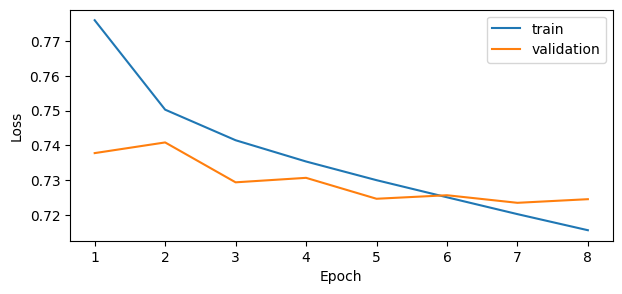

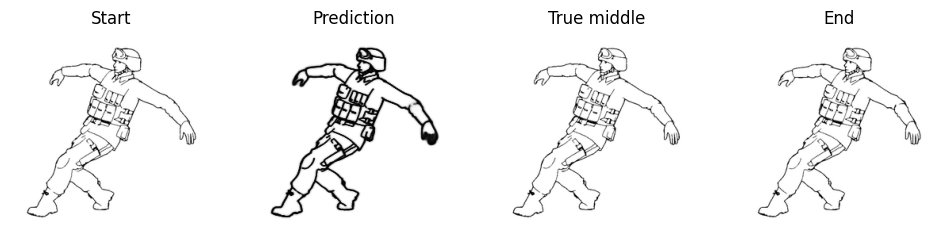

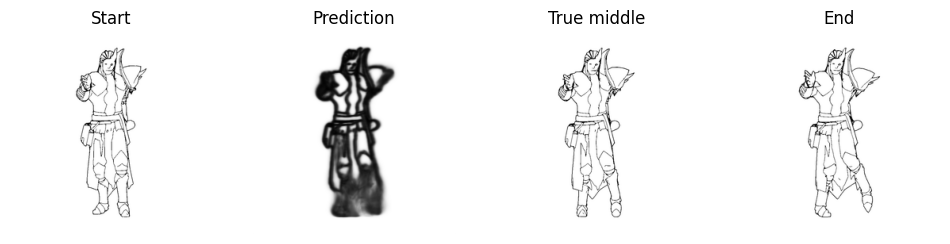

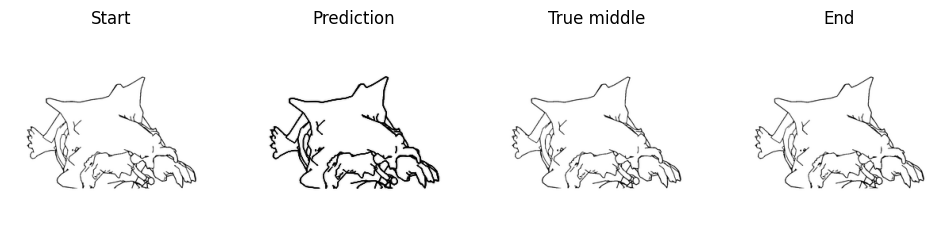

STAGE 2 COMPLETE: /kaggle/working/interframes_tf_stage2


In [ ]:
EPOCHS = 8
if initial_epoch < EPOCHS and (state is None or state["bad_epochs"] < PATIENCE):
    model.fit(
        train_data,
        validation_data=val_data,
        epochs=EPOCHS,
        initial_epoch=initial_epoch,
        callbacks=[callback, keras.callbacks.TerminateOnNaN()],
        shuffle=False,
        verbose=1,
    )

else:
    print("Requested epochs already completed, or early stopping was already reached.")


assert (OUT / "best.keras").exists(), "No completed epoch/checkpoint yet."


state = json.loads((OUT / "training_state.json").read_text())
best = keras.models.load_model(OUT / "best.keras", compile=False)
history = state["history"]
plt.figure(figsize=(7, 3))
plt.plot([h["epoch"] for h in history], [h["loss"] for h in history], label="train")
plt.plot(
    [h["epoch"] for h in history], [h["val_loss"] for h in history], label="validation"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
flows = raster.open_flows(DATA_ROOT, "val")


for i in np.linspace(0, len(val_rows) - 1, 3, dtype=int):
    r = val_rows[int(i)]
    p = learning.predict_cached(best, DATA_ROOT, r, flows)
    fig, axes = plt.subplots(1, 4, figsize=(12, 3))

    for ax, arr, title in zip(
        axes,
        [
            raster.read_ink(DATA_ROOT / r["a"]),
            p,
            raster.read_ink(DATA_ROOT / r["target"]),
            raster.read_ink(DATA_ROOT / r["b"]),
        ],
        ["Start", "Prediction", "True middle", "End"],
    ):
        ax.imshow(arr, cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")
    plt.show()

raster.json_save(
    OUT / "stage2_complete.json",
    dict(
        data_fingerprint=meta["fingerprint"],
        best_sha256=raster.digest(OUT / "best.keras"),
        completed_epochs=state["completed_epochs"],
        best_val=state["best_val"],
        scope="full",
        tensorflow=tf.__version__,
        keras=keras.__version__,
    ),
)


print("STAGE 2 COMPLETE:", OUT)


Epoch 9/10
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 0s 263ms/step - ink_mae: 0.1046 - loss: 0.7092Checkpoint saved at epoch 9; best val=0.72352
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 5643s 386ms/step - ink_mae: 0.1051 - loss: 0.7106 - val_ink_mae: 0.0955 - val_loss: 0.7285
Epoch 10/10
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - ink_mae: 0.1040 - loss: 0.7061Checkpoint saved at epoch 10; best val=0.72352
14598/14598 ━━━━━━━━━━━━━━━━━━━━ 4399s 301ms/step - ink_mae: 0.1040 - loss: 0.7061 - val_ink_mae: 0.0917 - val_loss: 0.7307


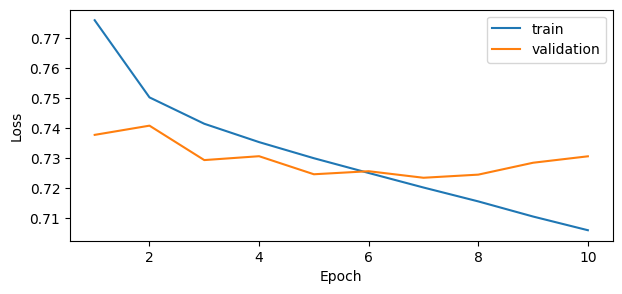

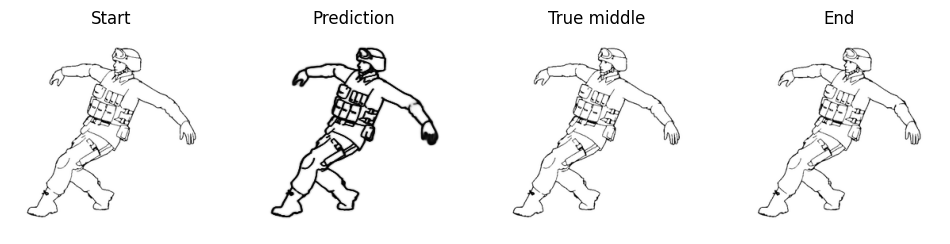

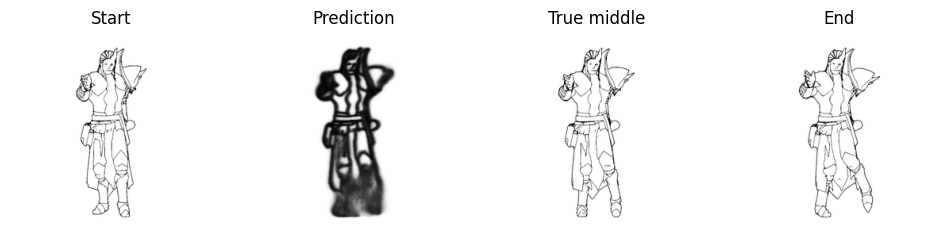

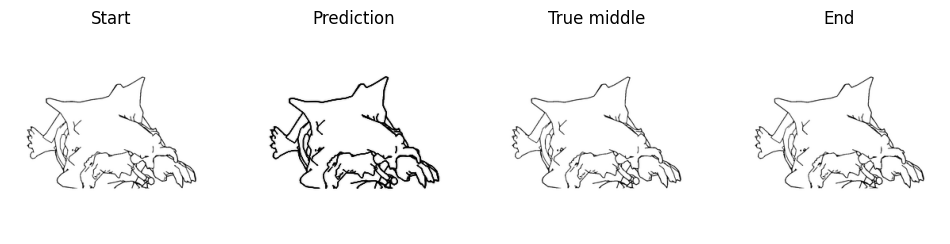

STAGE 2 COMPLETE: /kaggle/working/interframes_tf_stage2


In [ ]:
EPOCHS = 10
if initial_epoch < EPOCHS and (state is None or state["bad_epochs"] < PATIENCE):
    model.fit(
        train_data,
        validation_data=val_data,
        epochs=EPOCHS,
        initial_epoch=initial_epoch,
        callbacks=[callback, keras.callbacks.TerminateOnNaN()],
        shuffle=False,
        verbose=1,
    )

else:
    print("Requested epochs already completed, or early stopping was already reached.")


assert (OUT / "best.keras").exists(), "No completed epoch/checkpoint yet."


state = json.loads((OUT / "training_state.json").read_text())
best = keras.models.load_model(OUT / "best.keras", compile=False)
history = state["history"]
plt.figure(figsize=(7, 3))
plt.plot([h["epoch"] for h in history], [h["loss"] for h in history], label="train")
plt.plot(
    [h["epoch"] for h in history], [h["val_loss"] for h in history], label="validation"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
flows = raster.open_flows(DATA_ROOT, "val")


for i in np.linspace(0, len(val_rows) - 1, 3, dtype=int):
    r = val_rows[int(i)]
    p = learning.predict_cached(best, DATA_ROOT, r, flows)
    fig, axes = plt.subplots(1, 4, figsize=(12, 3))

    for ax, arr, title in zip(
        axes,
        [
            raster.read_ink(DATA_ROOT / r["a"]),
            p,
            raster.read_ink(DATA_ROOT / r["target"]),
            raster.read_ink(DATA_ROOT / r["b"]),
        ],
        ["Start", "Prediction", "True middle", "End"],
    ):
        ax.imshow(arr, cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")
    plt.show()

raster.json_save(
    OUT / "stage2_complete.json",
    dict(
        data_fingerprint=meta["fingerprint"],
        best_sha256=raster.digest(OUT / "best.keras"),
        completed_epochs=state["completed_epochs"],
        best_val=state["best_val"],
        scope="full",
        tensorflow=tf.__version__,
        keras=keras.__version__,
    ),
)


print("STAGE 2 COMPLETE:", OUT)


## Preview the latest checkpoint

Load `last.keras` and compare predicted middle drawings with their references. Its epoch depends on the saved checkpoint.

Loaded: /kaggle/working/interframes_tf_stage2/last.keras
Completed epochs: 10


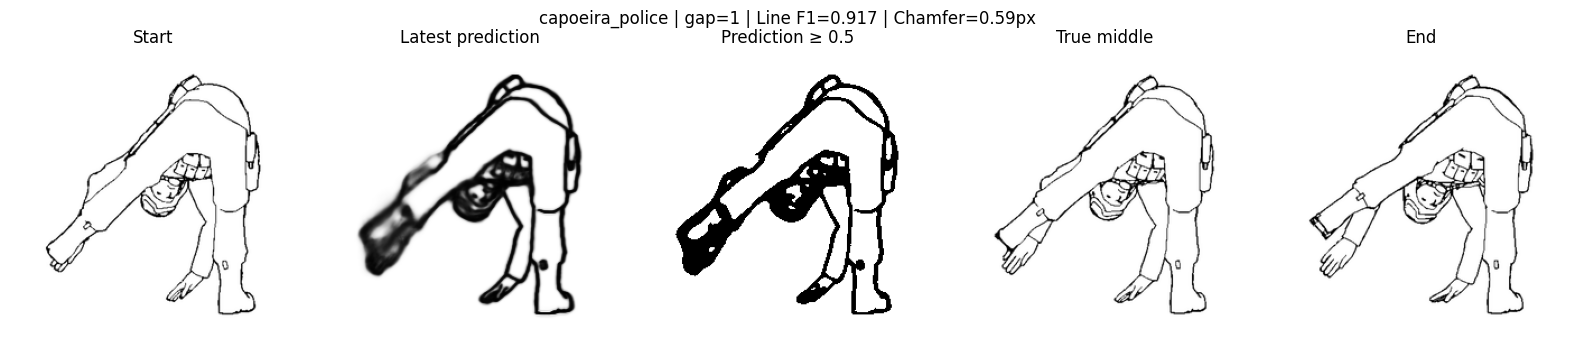

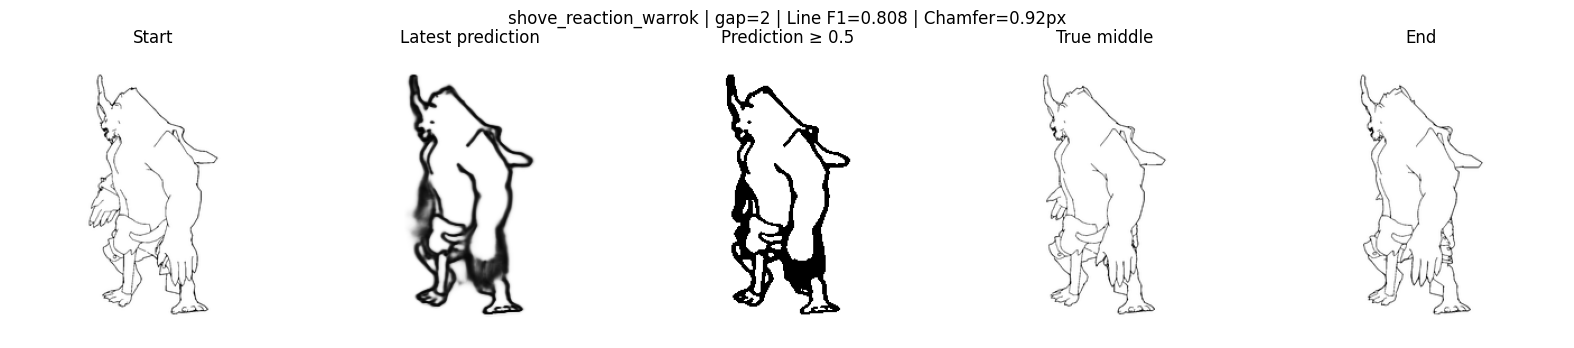

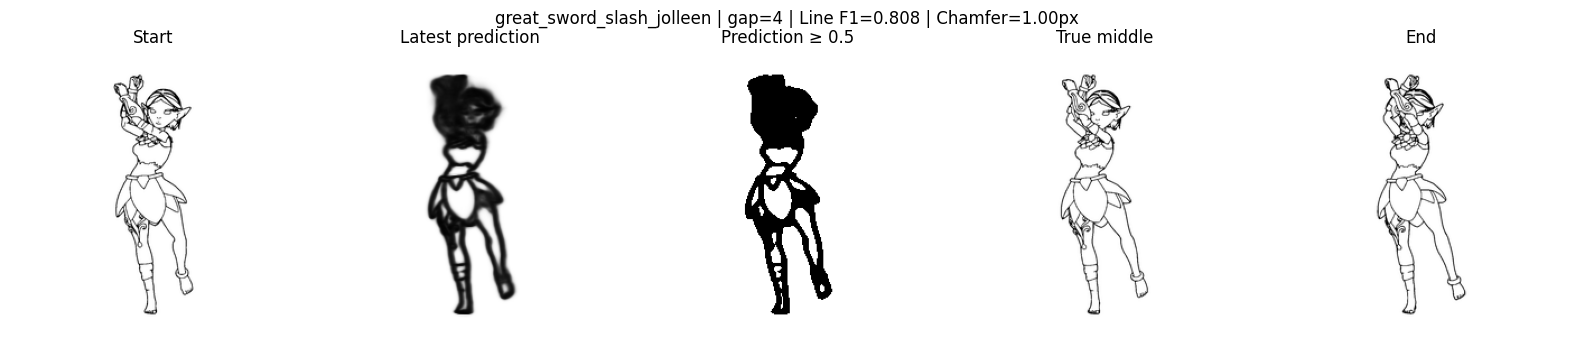

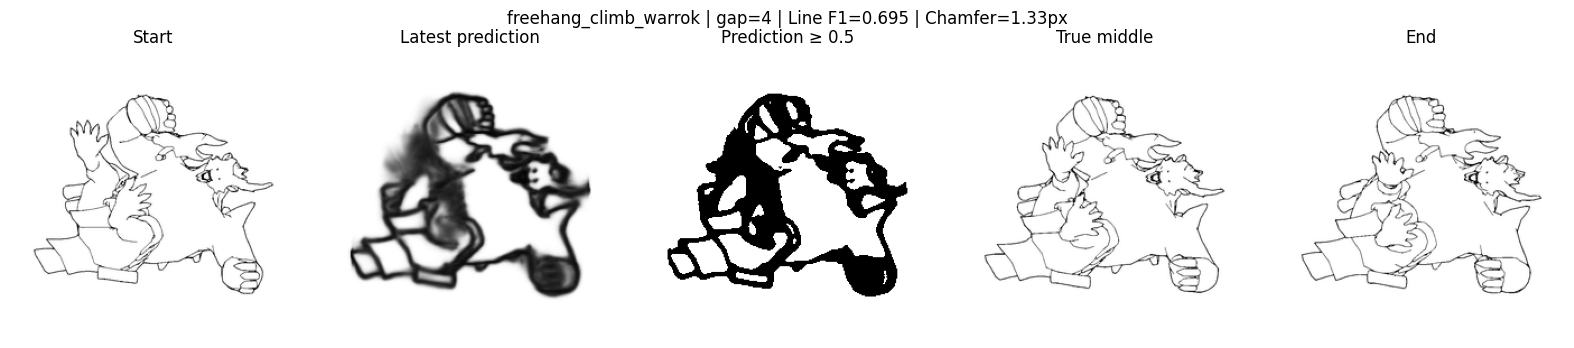

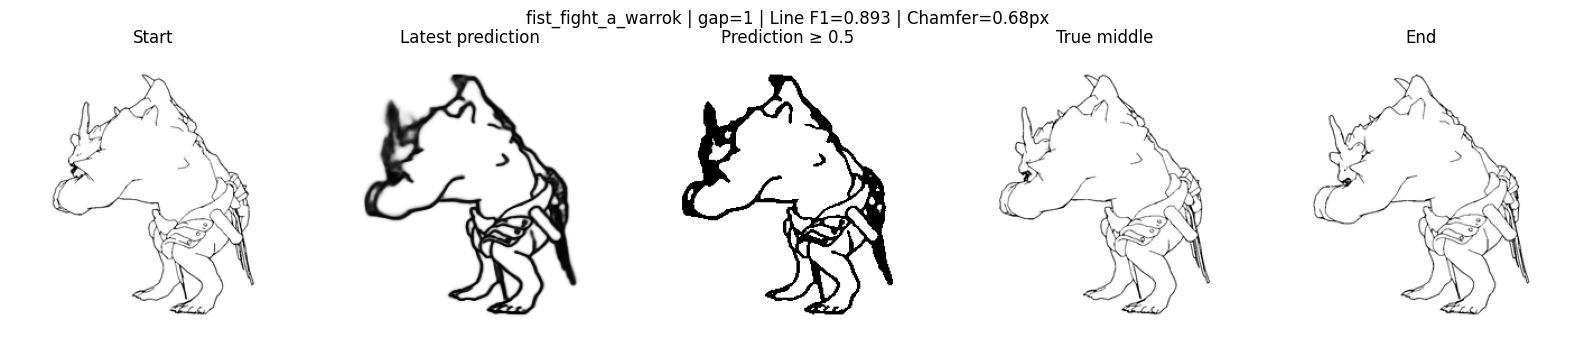

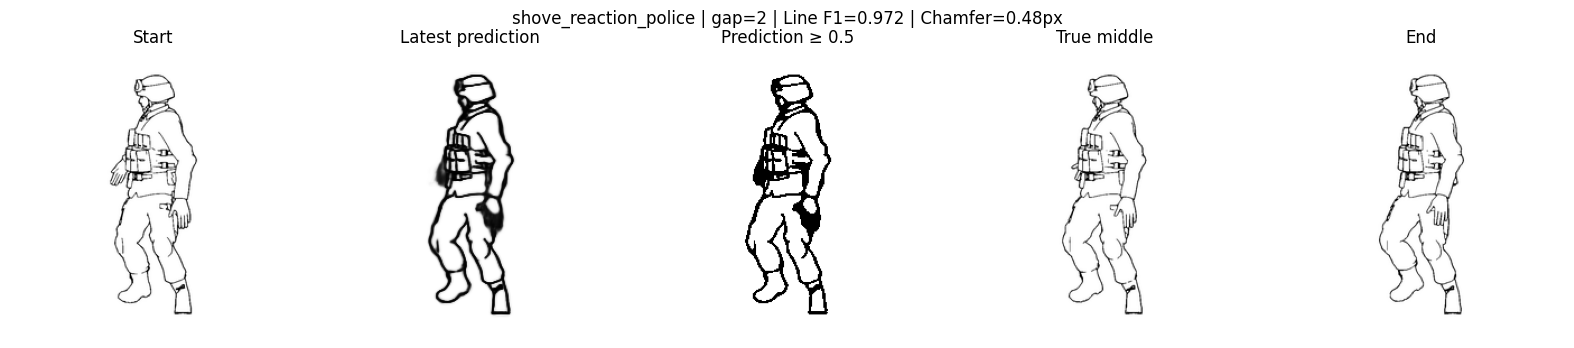

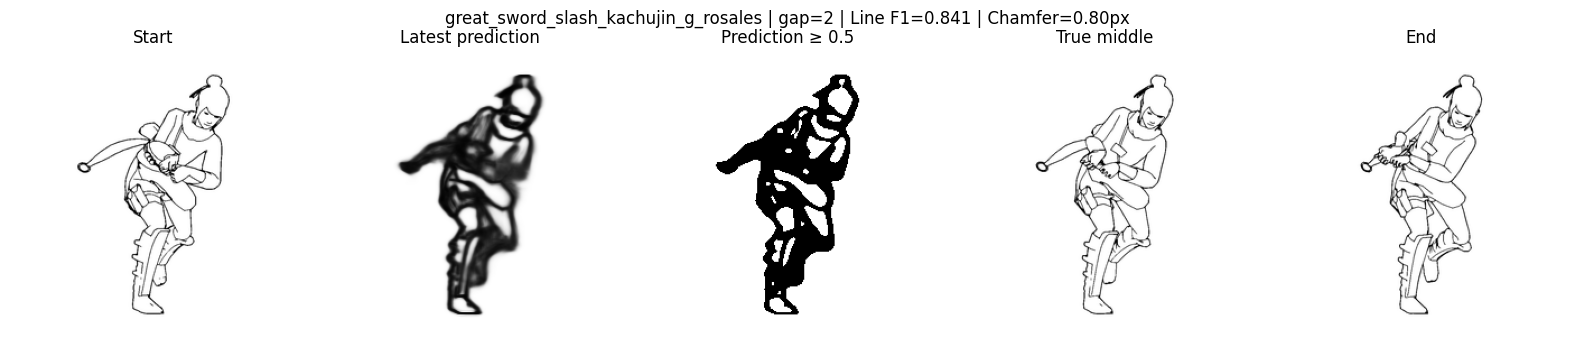

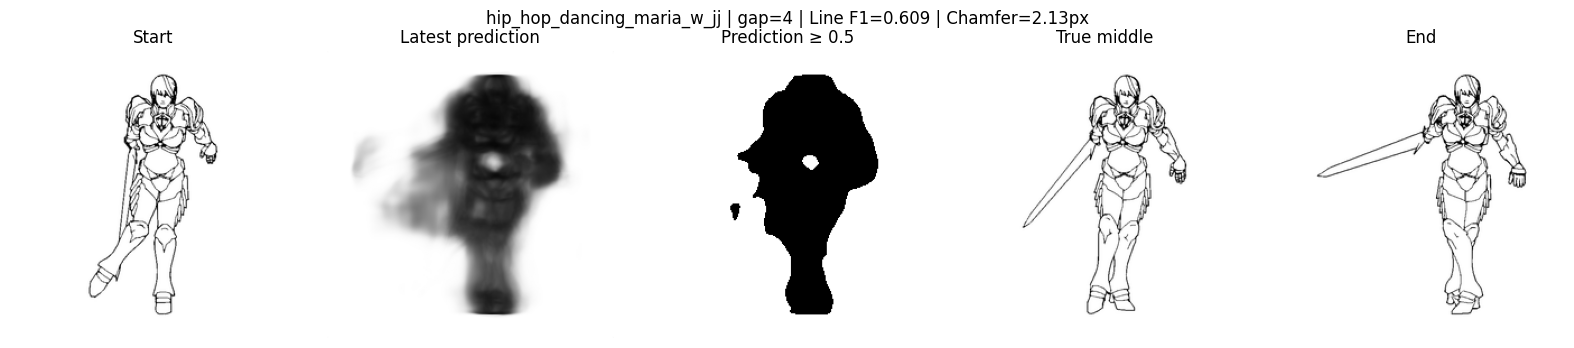

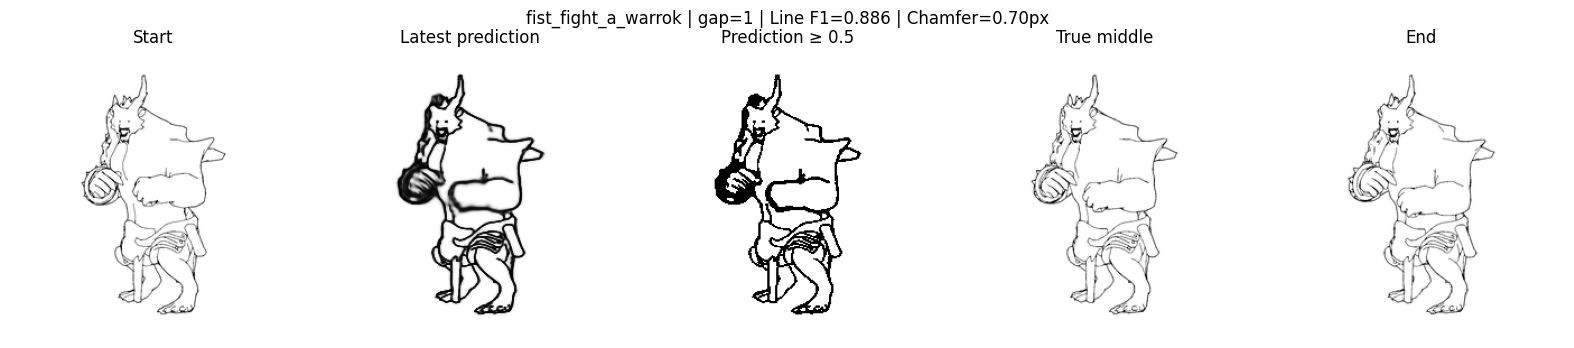

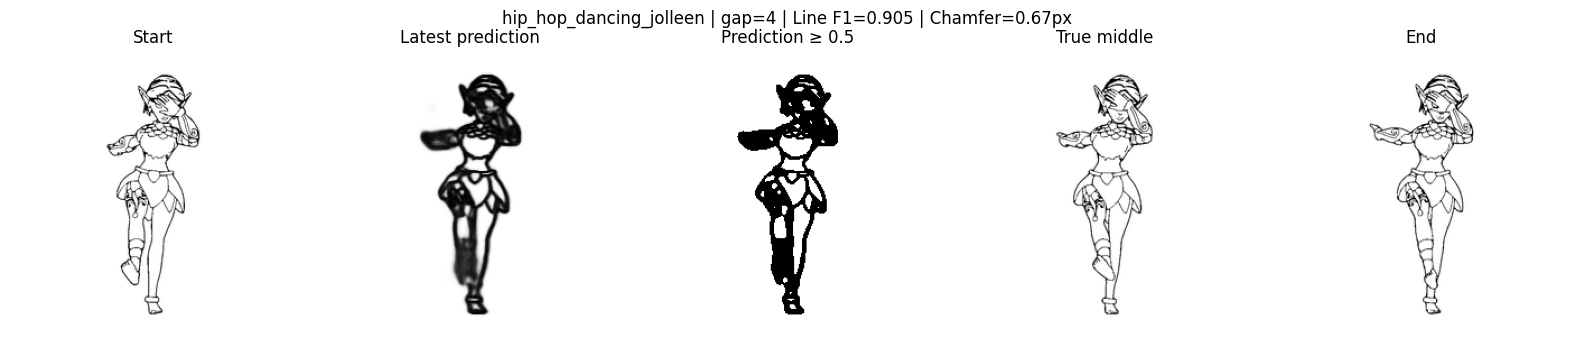

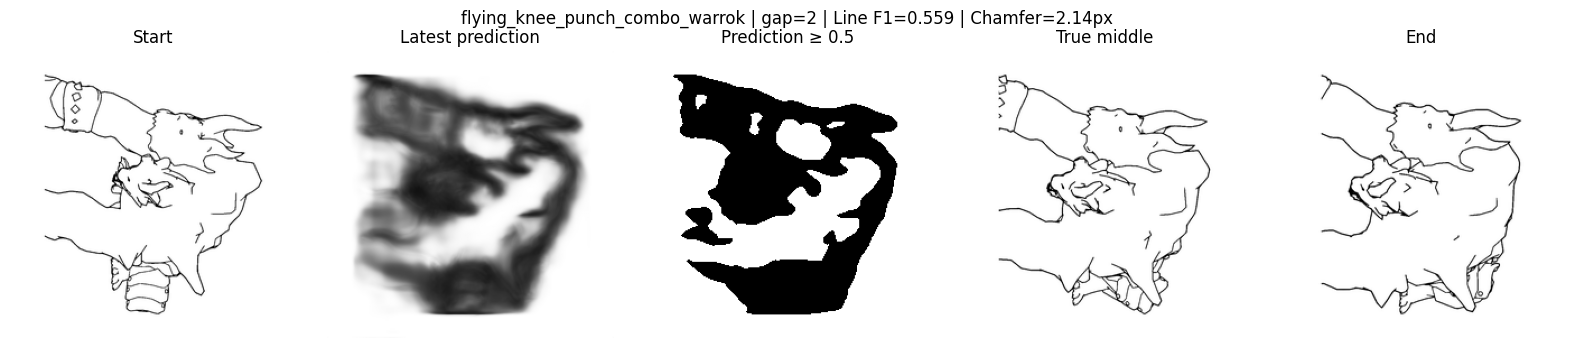

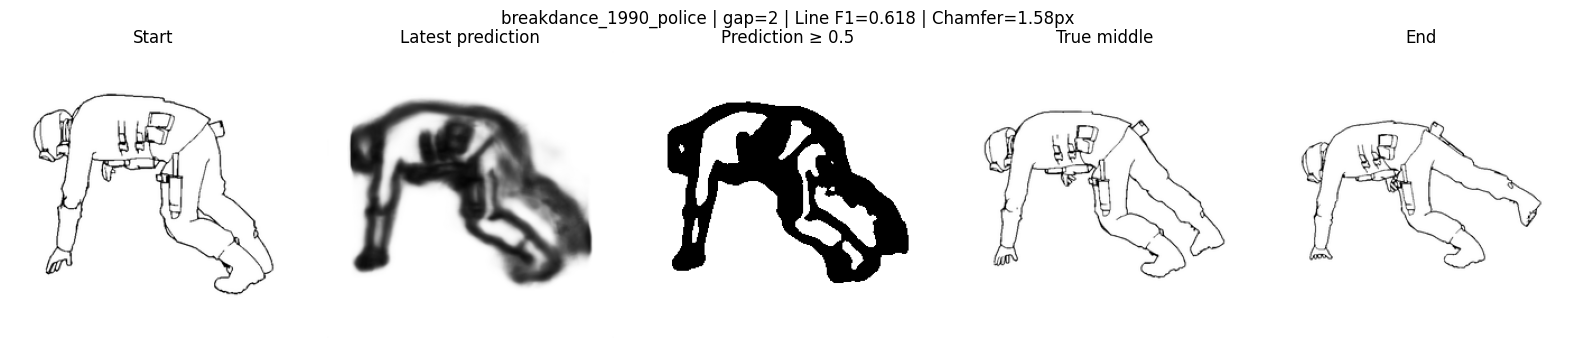

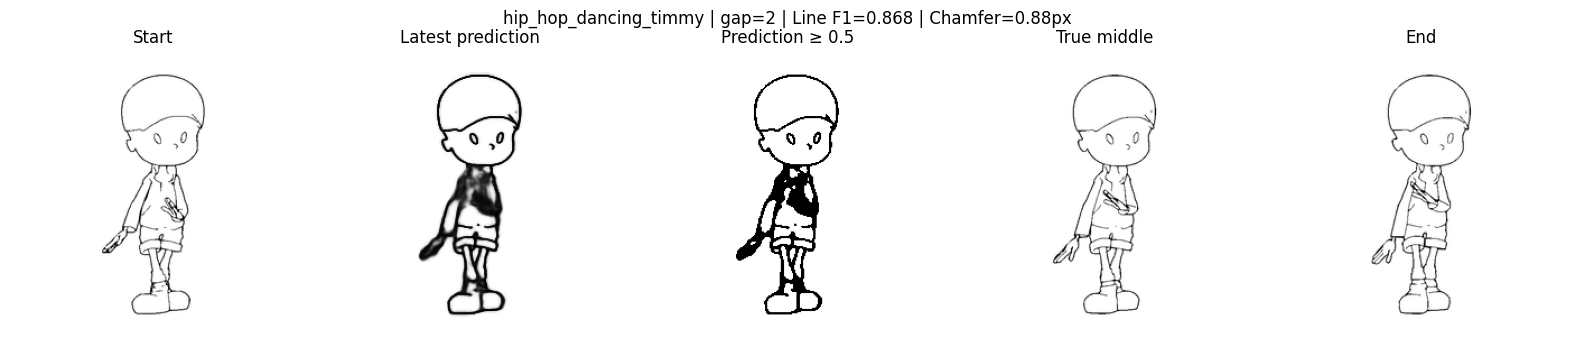

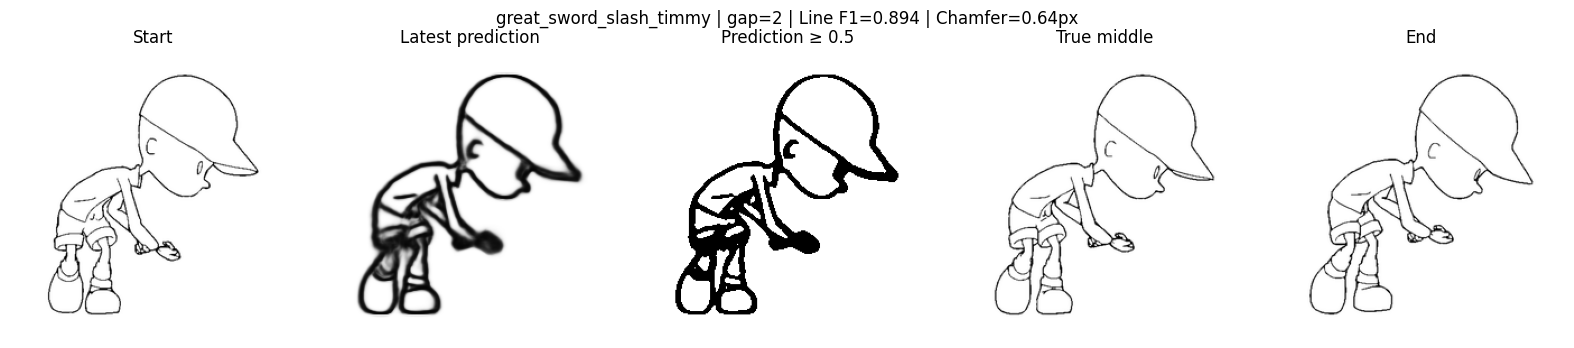

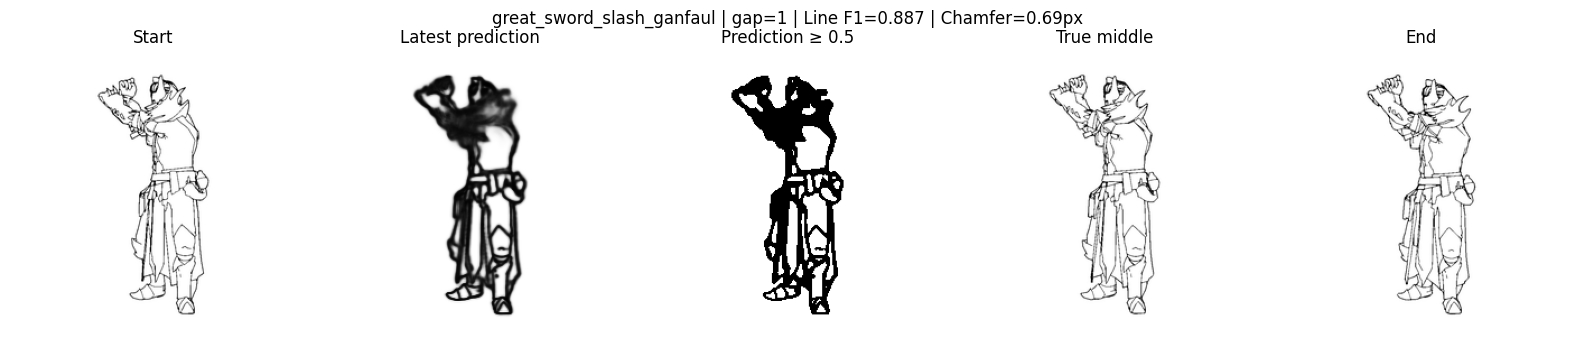

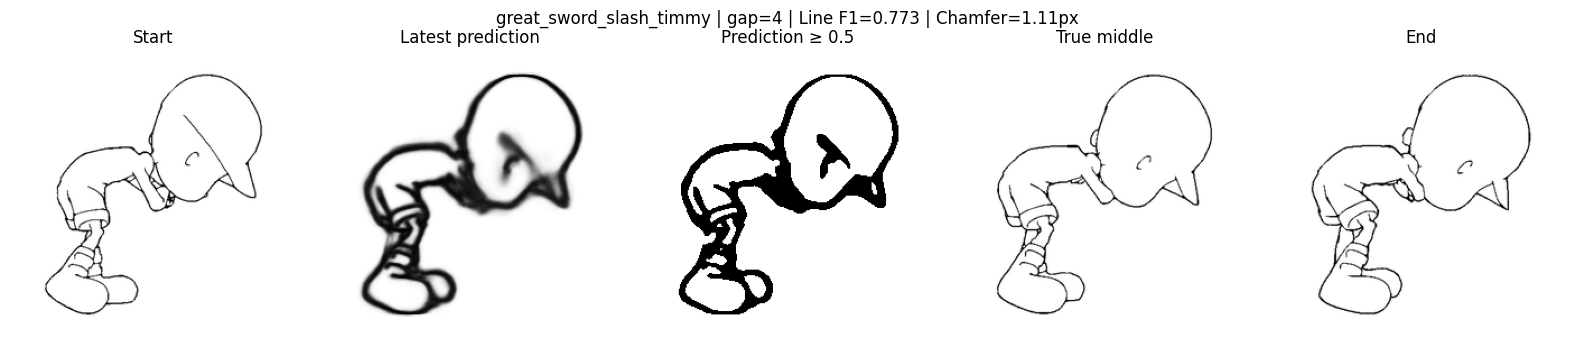

Previews saved to: /kaggle/working/interframes_tf_stage2/latest_model_previews


In [ ]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
import learning  # Registers the model's custom components. 

N_SAMPLES = 16
SAMPLE_SEED = 123  # Change this to see different drawings.

root = Path(DATA_ROOT)
checkpoint_dir = Path(OUT)
checkpoint = checkpoint_dir / "last.keras"

if not checkpoint.is_file():
    raise FileNotFoundError(checkpoint)

latest_model = keras.models.load_model(checkpoint, compile=False)
saved_state = json.loads((checkpoint_dir / "training_state.json").read_text())
print("Loaded:", checkpoint)
print("Completed epochs:", saved_state["completed_epochs"])

rows = [r for r in raster.read_records(root) if r["split"] == "val"]
flows = raster.open_flows(root, "val")

rng = np.random.default_rng(SAMPLE_SEED)
indices = rng.choice(len(rows), size=min(N_SAMPLES, len(rows)), replace=False)

preview_dir = checkpoint_dir / "latest_model_previews"
preview_dir.mkdir(parents=True, exist_ok=True)

for index in indices:
    row = rows[int(index)]

    prediction = learning.predict_cached(latest_model, root, row, flows)
    target = raster.read_ink(root / row["target"])
    scores = raster.line_scores(prediction, target, threshold=0.5, tolerance=2)

    images = [
        raster.read_ink(root / row["a"]),
        prediction,
        (prediction >= 0.5).astype(np.float32),
        target,
        raster.read_ink(root / row["b"]),
    ]
    titles = ["Start", "Latest prediction", "Prediction ≥ 0.5", "True middle", "End"]

    fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(
        f"{row['sequence']} | gap={row['gap']} | "
        f"Line F1={scores['line_f1']:.3f} | "
        f"Chamfer={scores['chamfer_px']:.2f}px"
    )
    fig.tight_layout()
    fig.savefig(preview_dir / f"{row['id']}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Previews saved to:", preview_dir)

## Preview the best checkpoint and restore training state

Load `best.keras`, selected by validation loss, and show the same kind of drawing comparisons. The following restore cell reloads the latest training state and sets `EPOCHS=8`; it does not train by itself.

Loaded: /kaggle/working/interframes_tf_stage2/best.keras
Completed epochs: 10


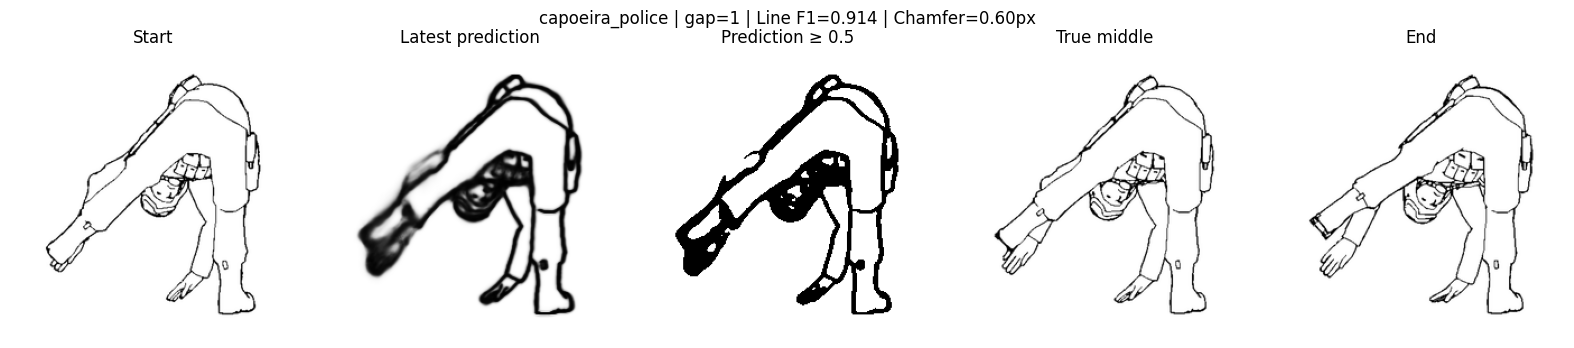

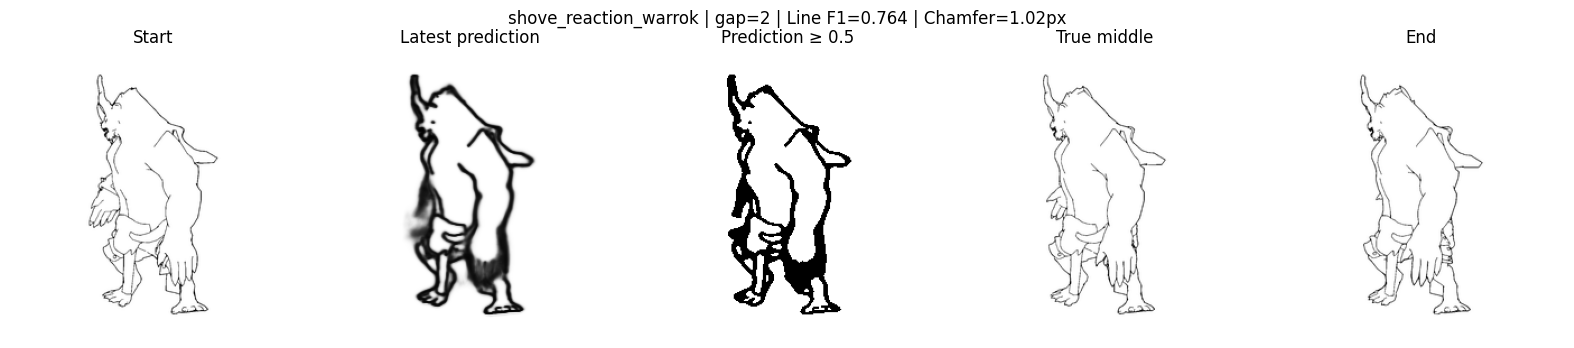

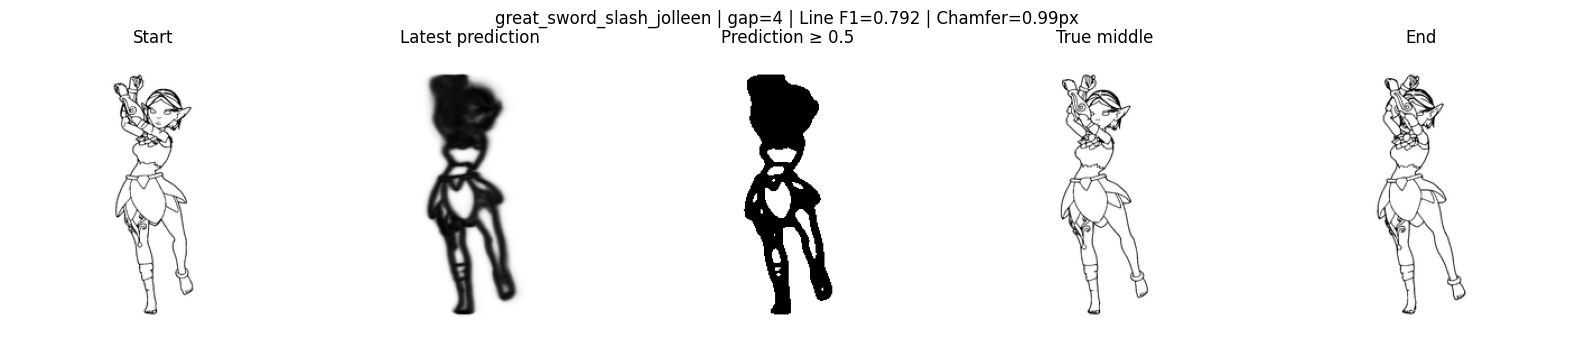

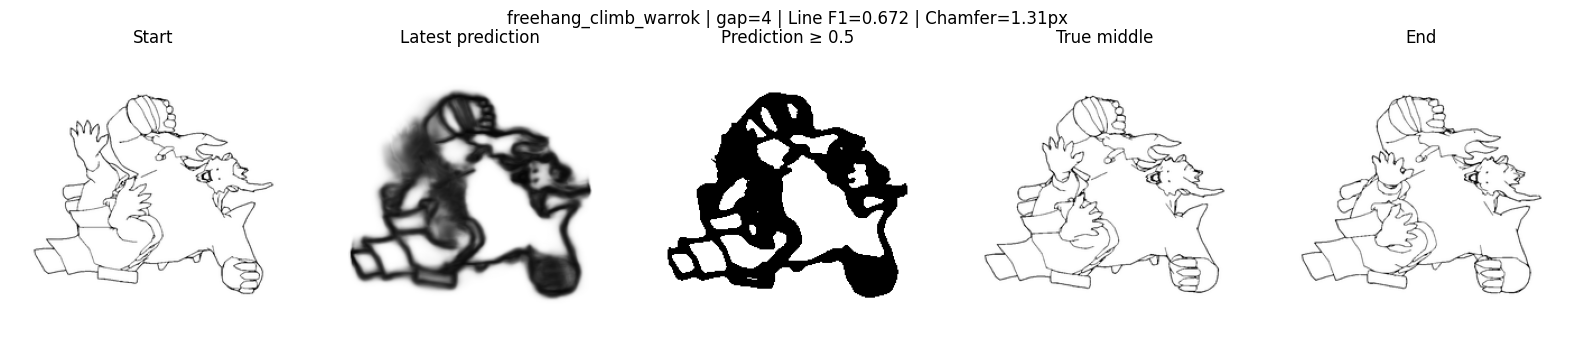

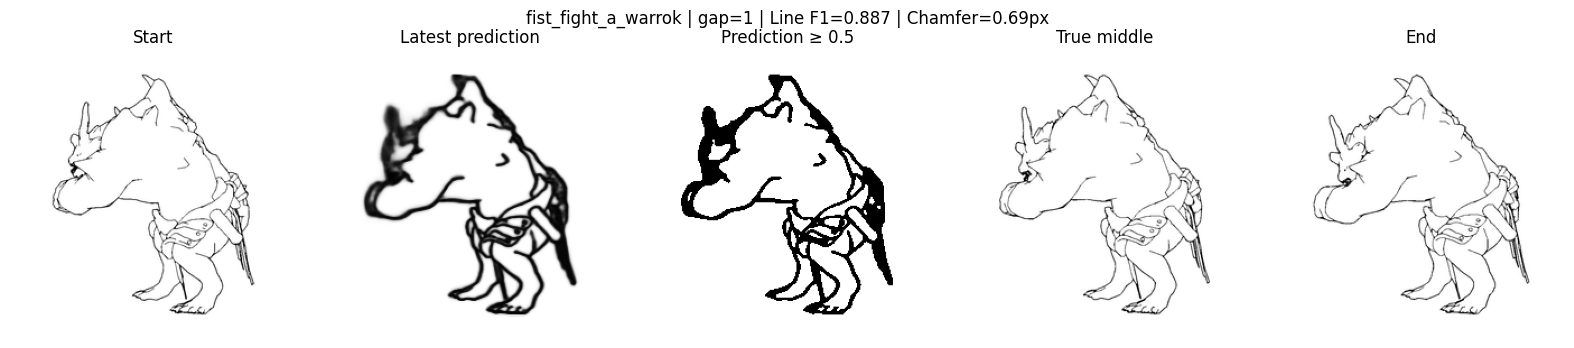

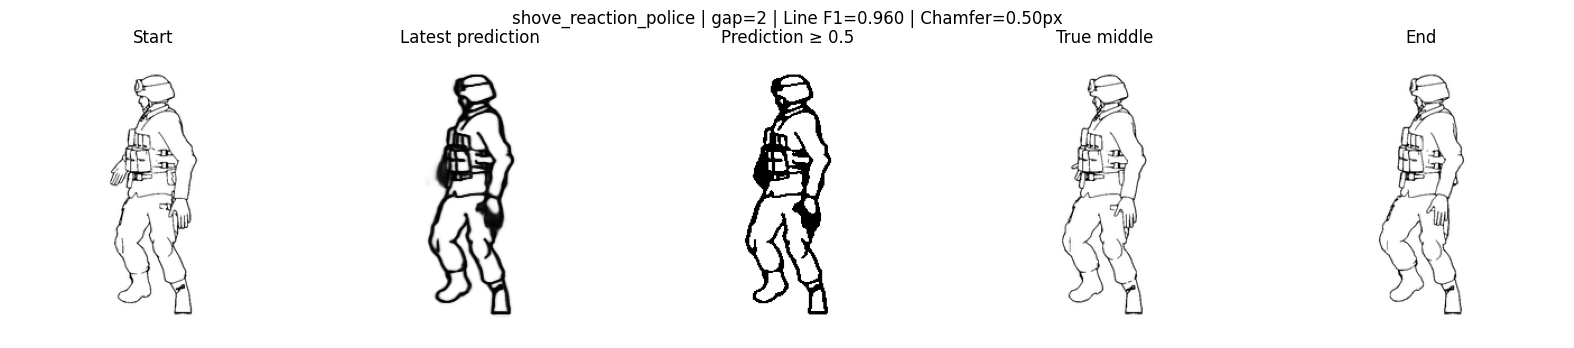

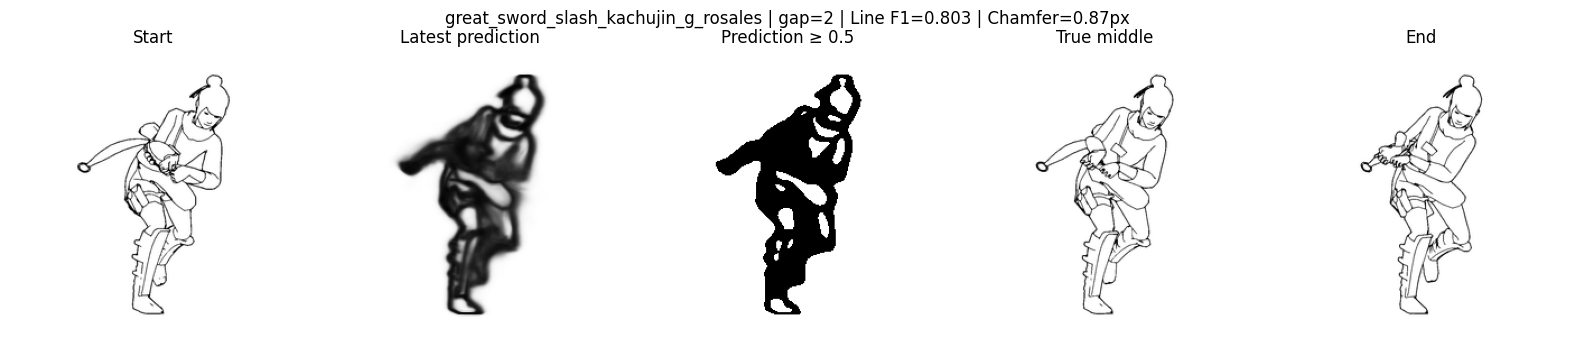

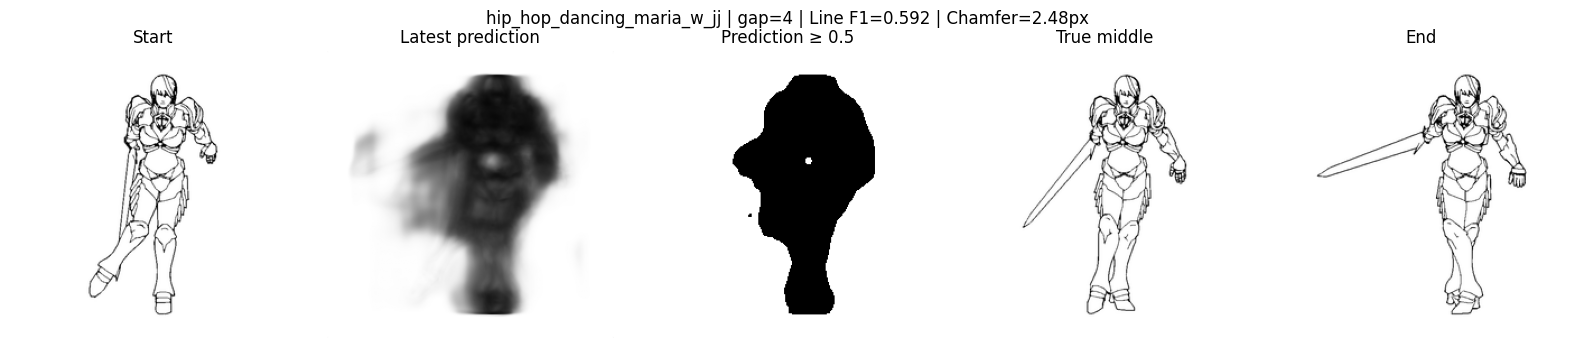

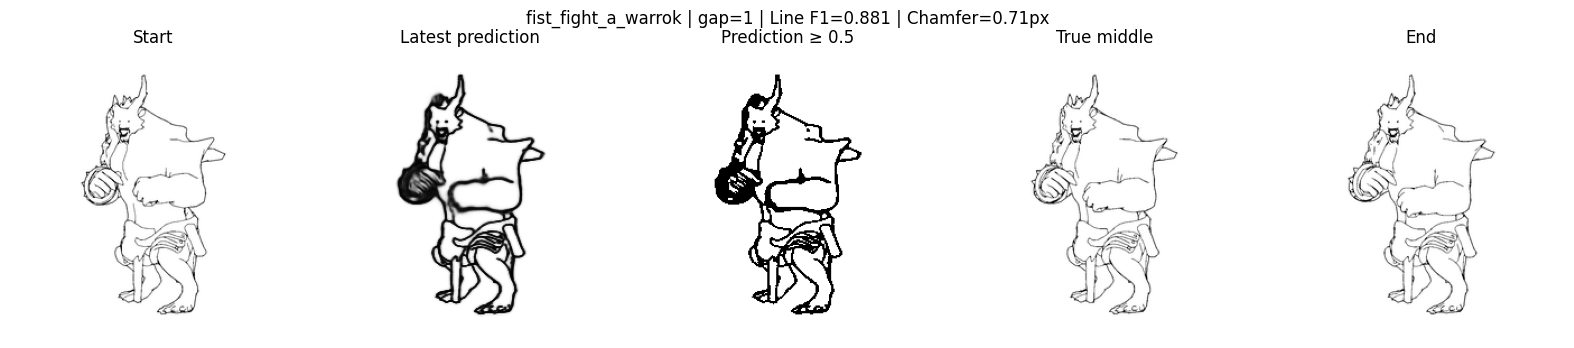

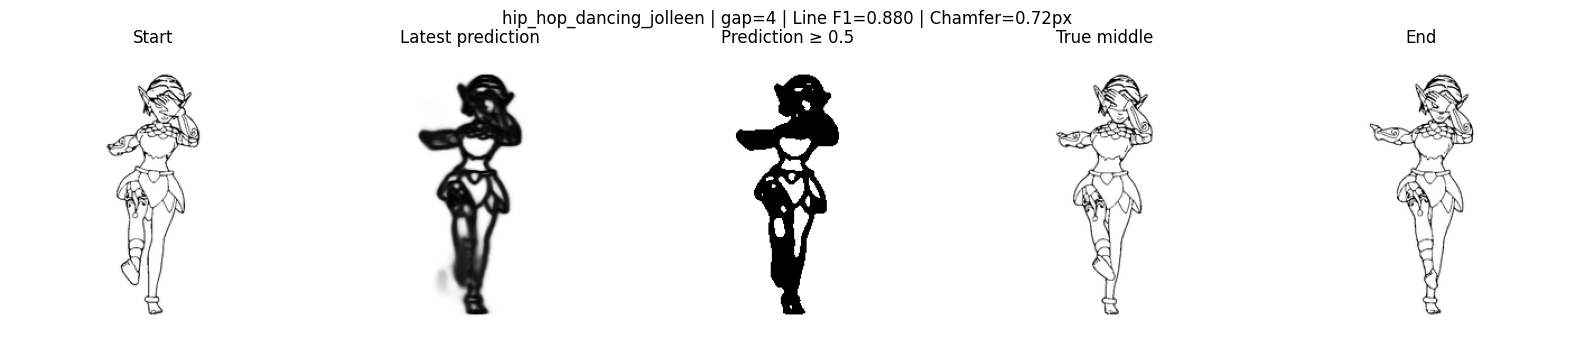

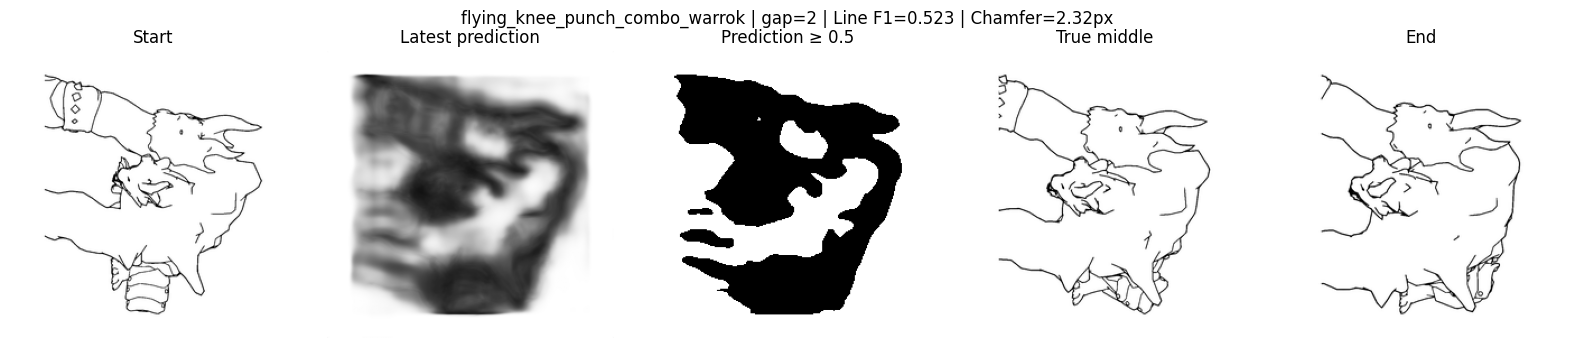

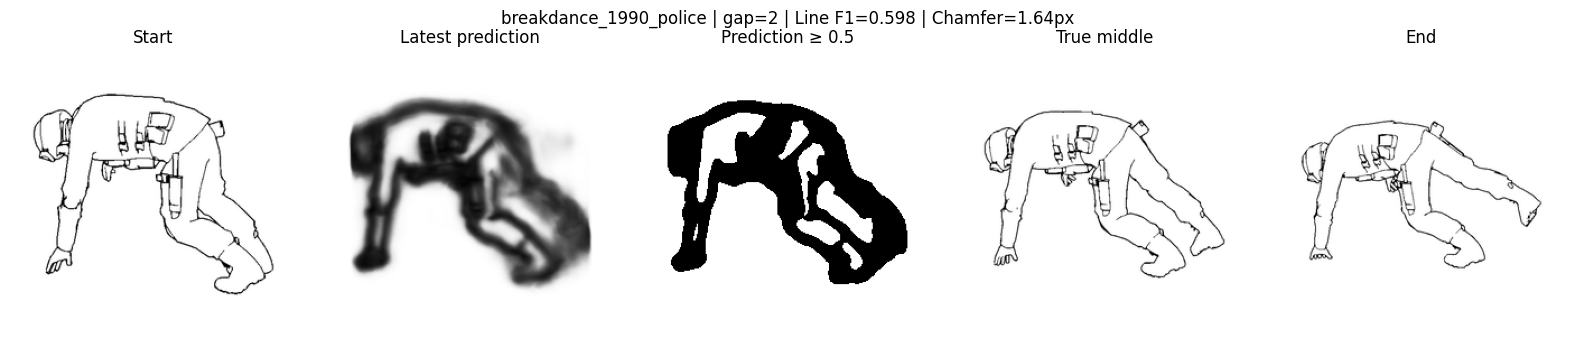

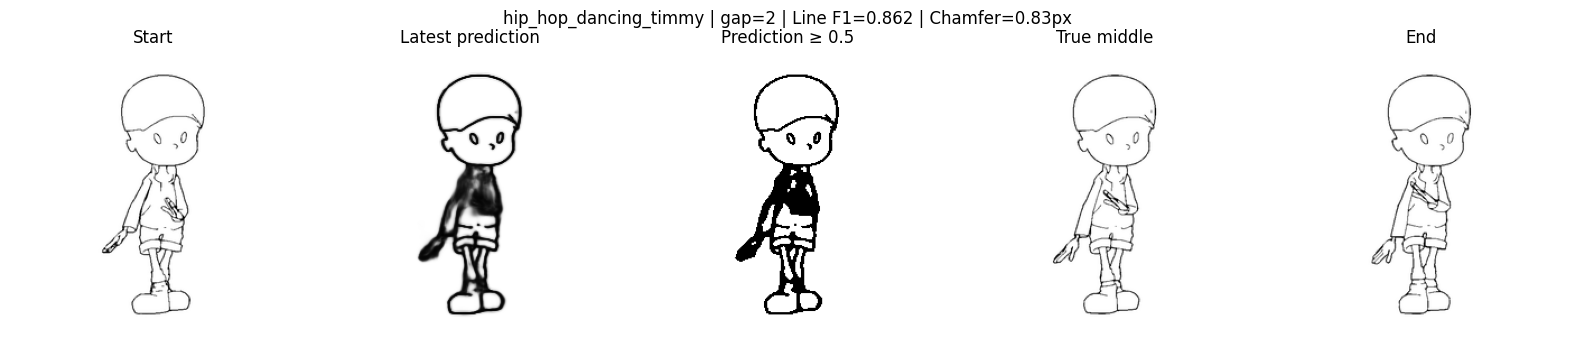

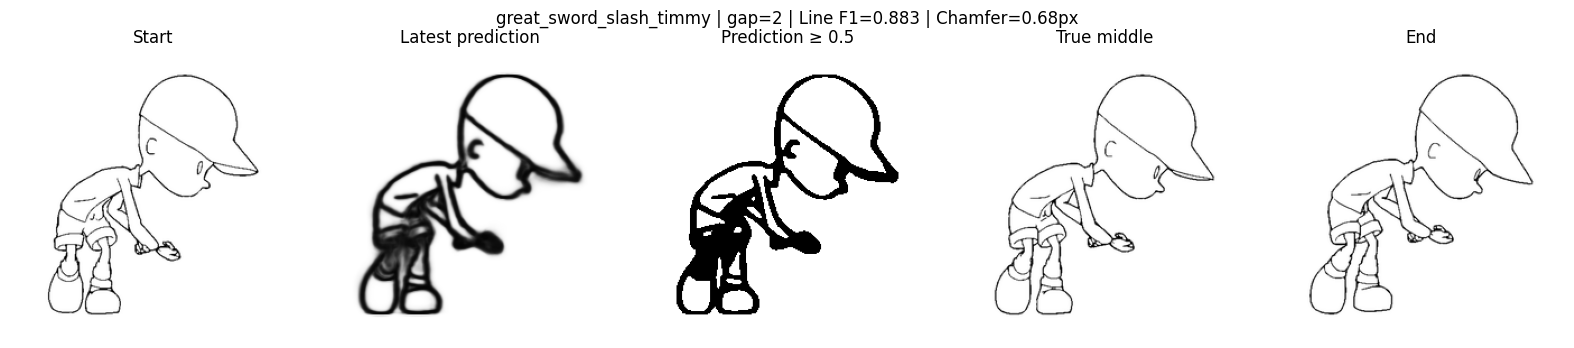

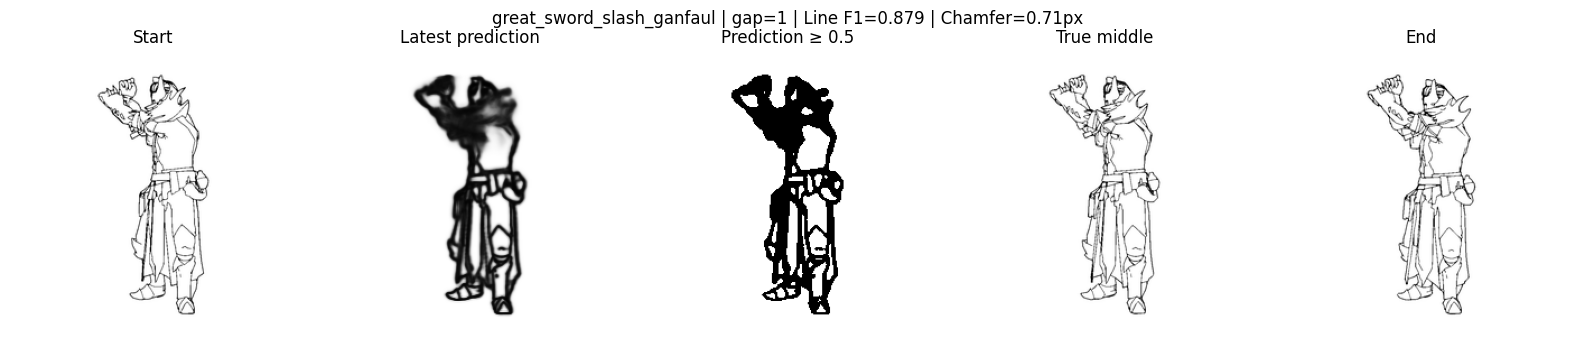

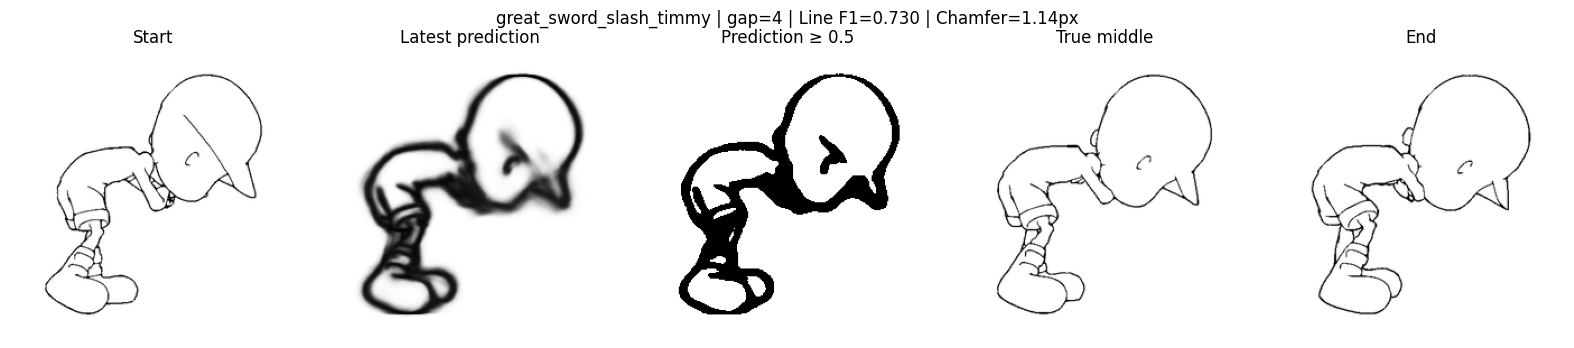

Previews saved to: /kaggle/working/interframes_tf_stage2/latest_model_previews


In [ ]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
import learning  # Registers the model's custom components.

N_SAMPLES = 16
SAMPLE_SEED = 123  # Change this to see different drawings.

root = Path(DATA_ROOT)
checkpoint_dir = Path(OUT)
checkpoint = checkpoint_dir / "best.keras"

if not checkpoint.is_file():
    raise FileNotFoundError(checkpoint)

latest_model = keras.models.load_model(checkpoint, compile=False)
saved_state = json.loads((checkpoint_dir / "training_state.json").read_text())
print("Loaded:", checkpoint)
print("Completed epochs:", saved_state["completed_epochs"])

rows = [r for r in raster.read_records(root) if r["split"] == "val"]
flows = raster.open_flows(root, "val")

rng = np.random.default_rng(SAMPLE_SEED)
indices = rng.choice(len(rows), size=min(N_SAMPLES, len(rows)), replace=False)

preview_dir = checkpoint_dir / "latest_model_previews"
preview_dir.mkdir(parents=True, exist_ok=True)

for index in indices:
    row = rows[int(index)]

    prediction = learning.predict_cached(latest_model, root, row, flows)
    target = raster.read_ink(root / row["target"])
    scores = raster.line_scores(prediction, target, threshold=0.5, tolerance=2)

    images = [
        raster.read_ink(root / row["a"]),
        prediction,
        (prediction >= 0.5).astype(np.float32),
        target,
        raster.read_ink(root / row["b"]),
    ]
    titles = ["Start", "Latest prediction", "Prediction ≥ 0.5", "True middle", "End"]

    fig, axes = plt.subplots(1, 5, figsize=(16, 3.5))
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image, cmap="gray_r", vmin=0, vmax=1)
        ax.set_title(title)
        ax.axis("off")

    fig.suptitle(
        f"{row['sequence']} | gap={row['gap']} | "
        f"Line F1={scores['line_f1']:.3f} | "
        f"Chamfer={scores['chamfer_px']:.2f}px"
    )
    fig.tight_layout()
    fig.savefig(preview_dir / f"{row['id']}.png", dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)

print("Previews saved to:", preview_dir)

In [ ]:
EPOCHS = 8

model, state = learning.restore_training(OUT, run_cfg, OUT)
initial_epoch = state["completed_epochs"]

if initial_epoch < 4:
    raise RuntimeError(
        f"This folder contains a checkpoint for epoch {initial_epoch}, "
        f"but we expected at least 4. Check the checkpoint folder: {OUT}"
    )

callback = learning.RunCheckpoint(OUT, run_cfg, initial_state=state, patience=PATIENCE)

train_data.epoch = initial_epoch
train_data.order = np.arange(len(train_data.rows))
np.random.default_rng(run_cfg["seed"] + initial_epoch).shuffle(train_data.order)

print(f"Checkpoint restored. Next epoch: {initial_epoch + 1}/{EPOCHS}")

Checkpoint restored. Next epoch: 5/8


## Save the run for another session

Each completed epoch saves model weights, optimizer state, and training progress. An interrupted epoch starts again. The following cells create a download ZIP and list available training states.

Keep the whole Stage 2 folder. On Kaggle, save a version that includes output files or download the ZIP before the session ends.

In [ ]:
from pathlib import Path
import os
import shutil
from IPython.display import FileLink, display

output = Path("/kaggle/working/interframes_tf_stage2")

if not output.is_dir():
    raise FileNotFoundError(
        "Run notebook 02 first so it creates the Stage 2 output folder."
    )

zip_path = shutil.make_archive(
    base_name="/kaggle/working/interframes_tf_stage2_models",
    format="zip",
    root_dir=output.parent,
    base_dir=output.name,
)

display(FileLink(os.path.relpath(zip_path), result_html_prefix="Click to download: "))

/kaggle/working/interframes_tf_stage2_models.zip

In [8]:
from pathlib import Path
import json

found = False
for root in (Path("/kaggle/working"), Path("/kaggle/input")):
    for state_file in root.rglob("training_state.json"):
        found = True
        state = json.loads(state_file.read_text())
        folder = state_file.parent
        print(f"Folder: {folder}")
        print(f"Completed epochs: {state.get('completed_epochs')}")
        print(f"last.keras exists: {(folder / 'last.keras').is_file()}")
        print()

if not found:
    print("No checkpoints in this session. Check saved versions' Output tabs.")

Folder: /kaggle/working/interframes_tf_stage2
Completed epochs: 10
last.keras exists: True

